# 01 — Multilingual Fine-Grained Sentiment Analysis
## BERT+BiLSTM (Multilingual) & XLM-RoBERTa on Trustpilot Reviews

Phase 2 moves to a harder, more fine-grained version of the sentiment task, on `company_trustpilot_reviews_hard.csv` (7 languages, ~500 reviews). Here I'm comparing two multilingual transformer setups directly against each other:

1. **BERT+BiLSTM** — `bert-base-multilingual-cased` feeding into a BiLSTM, an approach Nkhata et al. (2025) proposed for fine-grained sentiment on long movie reviews. I wanted to check whether that extra BiLSTM layer still earns its keep on much shorter customer reviews.
2. **XLM-RoBERTa** — `xlm-roberta-base` with a classification head, as a strong multilingual baseline to compare it against.

Running on Colab, ideally with a T4 GPU.


## Setting up the environment


In [1]:
# Install required packages
!pip install -q transformers torch datasets scikit-learn matplotlib seaborn pandas numpy tqdm

import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoTokenizer, AutoModel,
    get_linear_schedule_with_warmup
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_auc_score
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Using device: cuda
GPU: Tesla T4


### Connecting to Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Path Configuration
DRIVE_BASE = '/content/drive/MyDrive/ML_Sentiment_Analysis'
DATA_PATH = f'{DRIVE_BASE}/Sample_Data/company_trustpilot_reviews_hard.csv'
RESULTS_DIR = f'{DRIVE_BASE}/Results_Multilingual'

os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Data path:    {DATA_PATH}')
print(f'Results dir:  {RESULTS_DIR}')

## Loading and exploring the data


In [ ]:
df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
print(f'\n=== Sentiment Distribution ===')
print(df['sentiment_label'].value_counts())
print(f'\n=== Language Distribution ===')
print(df['language'].value_counts())
print(f'\n=== Rating Distribution ===')
print(df['rating'].value_counts().sort_index())
df.head()

> **Note:** I cleared the cached output of the cell above since it showed sample rows with the real company name — once you load the sanitized synthetic CSV, just re-run the cell to regenerate it.


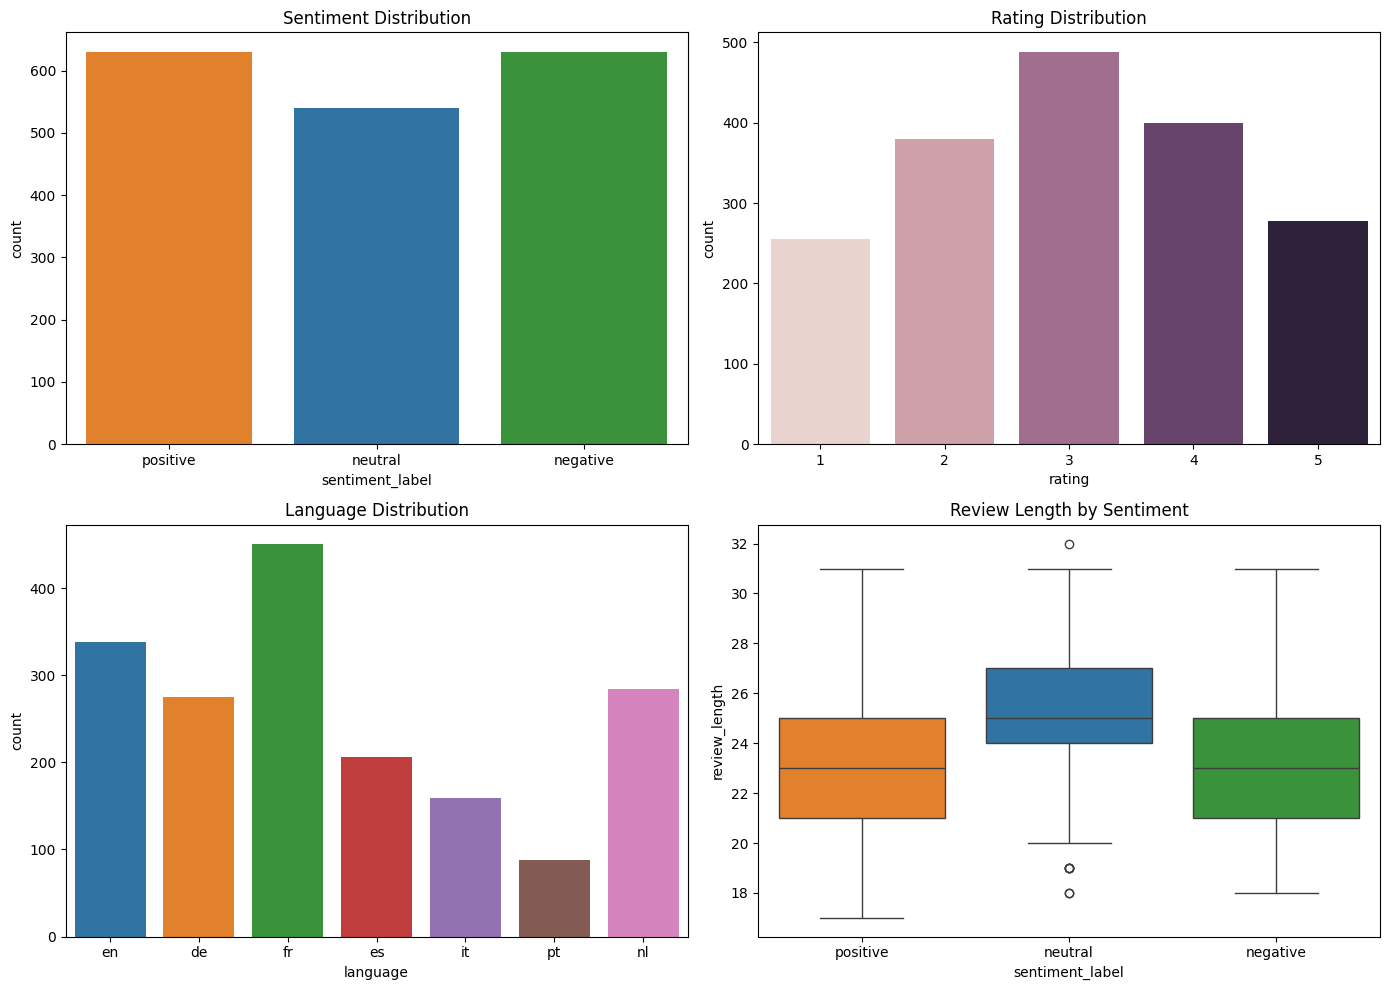

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='sentiment_label', ax=axes[0,0], hue='sentiment_label',
              order=['positive', 'neutral', 'negative'], legend=False)
axes[0,0].set_title('Sentiment Distribution')

sns.countplot(data=df, x='rating', ax=axes[0,1], hue='rating', legend=False)
axes[0,1].set_title('Rating Distribution')

sns.countplot(data=df, x='language', ax=axes[1,0], hue='language', legend=False)
axes[1,0].set_title('Language Distribution')

df['review_length'] = df['review_text'].str.split().str.len()
sns.boxplot(data=df, x='sentiment_label', y='review_length', ax=axes[1,1],
            hue='sentiment_label', order=['positive', 'neutral', 'negative'], legend=False)
axes[1,1].set_title('Review Length by Sentiment')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/exploration_plots.png', dpi=150, bbox_inches='tight')
plt.show()

## Preprocessing the data


In [5]:
import re

def preprocess_text(text):
    if pd.isna(text):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^\w\s\u00C0-\u024F]', '', text)  # keep accented chars
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Combine title + body
df['combined_text'] = df['review_title'].fillna('') + ' ' + df['review_text'].fillna('')
df['processed_text'] = df['combined_text'].apply(preprocess_text)

# Encode labels
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['sentiment_label'])
NUM_CLASSES = len(label_encoder.classes_)
print(f'Classes: {list(label_encoder.classes_)}')
print(f'Num classes: {NUM_CLASSES}')

# Split: 70/15/15
X = df['processed_text'].values
y = df['label'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f'\nTrain: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}')

Classes: ['negative', 'neutral', 'positive']
Num classes: 3

Train: 1260, Val: 270, Test: 270


## PyTorch Dataset & DataLoader


In [6]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

def create_dataloaders(X_train, y_train, X_val, y_val, X_test, y_test, tokenizer, batch_size=32, max_len=128):
    train_ds = SentimentDataset(X_train, y_train, tokenizer, max_len)
    val_ds = SentimentDataset(X_val, y_val, tokenizer, max_len)
    test_ds = SentimentDataset(X_test, y_test, tokenizer, max_len)

    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_dl = DataLoader(val_ds, batch_size=batch_size)
    test_dl = DataLoader(test_ds, batch_size=batch_size)

    return train_dl, val_dl, test_dl

print('Dataset and DataLoader classes defined.')

Dataset and DataLoader classes defined.


## Model 1: BERT + BiLSTM (multilingual)

This is the architecture inspired by Nkhata et al. (2025): multilingual BERT's token embeddings feed into a BiLSTM before the classification head, rather than classifying directly off BERT's `[CLS]` token.


In [7]:
class BERTBiLSTM(nn.Module):
    def __init__(self, model_name='bert-base-multilingual-cased', num_classes=3,
                 lstm_hidden=128, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        # Freeze early BERT layers (keep last 2 layers trainable)
        for param in self.bert.parameters():
            param.requires_grad = False
        for param in self.bert.encoder.layer[-2:].parameters():
            param.requires_grad = True
        for param in self.bert.pooler.parameters():
            param.requires_grad = True

        hidden_size = self.bert.config.hidden_size  # 768
        self.bilstm = nn.LSTM(hidden_size, lstm_hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(lstm_hidden * 2, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        sequence_output = outputs.last_hidden_state  # (batch, seq_len, 768)
        lstm_out, _ = self.bilstm(sequence_output)   # (batch, seq_len, 256)
        # Take last hidden state
        lstm_out = lstm_out[:, -1, :]                # (batch, 256)
        x = self.dropout(lstm_out)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

print('BERTBiLSTM model class defined.')

BERTBiLSTM model class defined.


### Training & evaluation functions


In [8]:
def train_epoch(model, dataloader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for batch in tqdm(dataloader, desc='Training', leave=False):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, acc, f1

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, acc, f1, np.array(all_preds), np.array(all_labels), np.array(all_probs)

print('Training and evaluation functions defined.')

Training and evaluation functions defined.


### Training BERT+BiLSTM


In [9]:
# Hyperparameters
BERT_MODEL = 'bert-base-multilingual-cased'
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 15
LR = 2e-5
PATIENCE = 3

# Tokenizer & Dataloaders
tokenizer_bert = AutoTokenizer.from_pretrained(BERT_MODEL)
train_dl, val_dl, test_dl = create_dataloaders(
    X_train, y_train, X_val, y_val, X_test, y_test,
    tokenizer_bert, batch_size=BATCH_SIZE, max_len=MAX_LEN
)

# Model
model_bert_bilstm = BERTBiLSTM(BERT_MODEL, NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(filter(lambda p: p.requires_grad, model_bert_bilstm.parameters()), lr=LR, weight_decay=0.01)
total_steps = len(train_dl) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1*total_steps), num_training_steps=total_steps)

# Training loop
history_bert = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_f1': [], 'val_f1': []}
best_val_f1 = 0
patience_counter = 0
start_time = time.time()

for epoch in range(EPOCHS):
    train_loss, train_acc, train_f1 = train_epoch(model_bert_bilstm, train_dl, optimizer, scheduler, criterion, device)
    val_loss, val_acc, val_f1, _, _, _ = evaluate(model_bert_bilstm, val_dl, criterion, device)

    history_bert['train_loss'].append(train_loss)
    history_bert['val_loss'].append(val_loss)
    history_bert['train_acc'].append(train_acc)
    history_bert['val_acc'].append(val_acc)
    history_bert['train_f1'].append(train_f1)
    history_bert['val_f1'].append(val_f1)

    print(f'Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f}')

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model_bert_bilstm.state_dict(), f'{RESULTS_DIR}/bert_bilstm_best.pt')
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}')
            break

bert_bilstm_time = time.time() - start_time
print(f'\nTraining completed in {bert_bilstm_time:.1f}s')

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

...

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 14/15 | Train Loss: 0.3588 Acc: 0.9627 F1: 0.9628 | Val Loss: 0.2989 Acc: 0.9667 F1: 0.9672


Training:   0%|          | 0/40 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 15/15 | Train Loss: 0.3449 Acc: 0.9698 F1: 0.9701 | Val Loss: 0.2971 Acc: 0.9630 F1: 0.9636

Training completed in 268.6s


### Evaluating BERT+BiLSTM on the test set


In [10]:
# Load best model
model_bert_bilstm.load_state_dict(torch.load(f'{RESULTS_DIR}/bert_bilstm_best.pt'))
_, test_acc_bert, test_f1_bert, preds_bert, labels_bert, probs_bert = evaluate(model_bert_bilstm, test_dl, criterion, device)

# AUC-ROC
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(labels_bert, classes=[0, 1, 2])
try:
    auc_bert = roc_auc_score(y_test_bin, probs_bert, multi_class='ovr', average='macro')
except:
    auc_bert = 0.0

f1_weighted_bert = f1_score(labels_bert, preds_bert, average='weighted')

print('=' * 50)
print('BERT+BiLSTM (Multilingual) — TEST RESULTS')
print('=' * 50)
print(f'Accuracy:       {test_acc_bert:.4f}')
print(f'F1 (macro):     {test_f1_bert:.4f}')
print(f'F1 (weighted):  {f1_weighted_bert:.4f}')
print(f'AUC-ROC:        {auc_bert:.4f}')
print(f'Training time:  {bert_bilstm_time:.1f}s')
print('=' * 50)
print('\nClassification Report:')
print(classification_report(labels_bert, preds_bert, target_names=label_encoder.classes_, digits=4))

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

BERT+BiLSTM (Multilingual) — TEST RESULTS
Accuracy:       0.9778
F1 (macro):     0.9786
F1 (weighted):  0.9778
AUC-ROC:        0.9977
Training time:  268.6s

Classification Report:
              precision    recall  f1-score   support

    negative     0.9684    0.9684    0.9684        95
     neutral     1.0000    0.9877    0.9938        81
    positive     0.9684    0.9787    0.9735        94

    accuracy                         0.9778       270
   macro avg     0.9789    0.9783    0.9786       270
weighted avg     0.9779    0.9778    0.9778       270



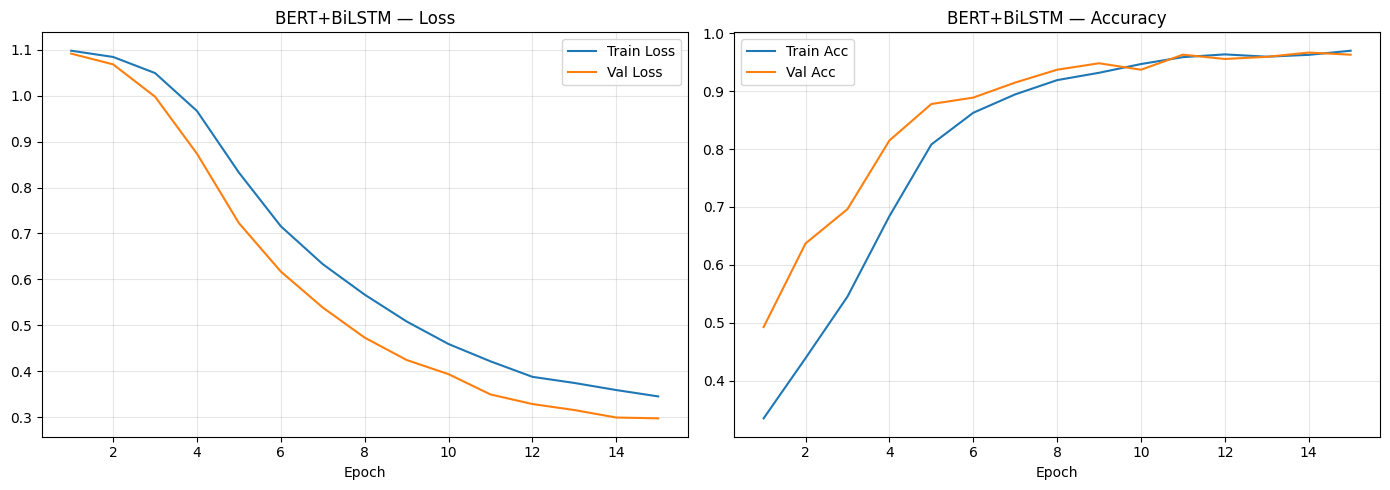

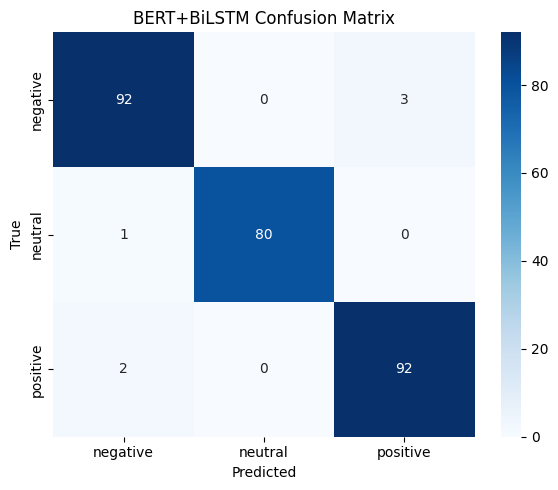

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, len(history_bert['train_loss']) + 1)

axes[0].plot(epochs_range, history_bert['train_loss'], label='Train Loss')
axes[0].plot(epochs_range, history_bert['val_loss'], label='Val Loss')
axes[0].set_title('BERT+BiLSTM — Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history_bert['train_acc'], label='Train Acc')
axes[1].plot(epochs_range, history_bert['val_acc'], label='Val Acc')
axes[1].set_title('BERT+BiLSTM — Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/bert_bilstm_multilingual_training.png', dpi=150, bbox_inches='tight')
plt.show()

# Confusion matrix
cm_bert = confusion_matrix(labels_bert, preds_bert)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=ax)
ax.set_title('BERT+BiLSTM Confusion Matrix'); ax.set_ylabel('True'); ax.set_xlabel('Predicted')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/bert_bilstm_multilingual_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## Model 2: XLM-RoBERTa

The second model is more straightforward — `xlm-roberta-base` with a standard classification head on top:

```
Input → xlm-roberta-base → [CLS] token → Dense (256, ReLU) → Dropout (0.3) → Softmax (3)
```

This gives me a clean comparison point: does the extra BiLSTM in Model 1 actually buy anything over a more conventional multilingual transformer setup?


In [12]:
class XLMRoBERTaClassifier(nn.Module):
    def __init__(self, model_name='xlm-roberta-base', num_classes=3, dropout=0.3):
        super().__init__()
        self.roberta = AutoModel.from_pretrained(model_name)
        # Freeze all except last 2 layers + pooler
        for param in self.roberta.parameters():
            param.requires_grad = False
        for param in self.roberta.encoder.layer[-2:].parameters():
            param.requires_grad = True

        hidden_size = self.roberta.config.hidden_size  # 768
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_size, 256)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        cls_output = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        x = self.dropout(cls_output)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# XLM-RoBERTa setup
XLM_MODEL = 'xlm-roberta-base'
tokenizer_xlm = AutoTokenizer.from_pretrained(XLM_MODEL)
train_dl2, val_dl2, test_dl2 = create_dataloaders(
    X_train, y_train, X_val, y_val, X_test, y_test,
    tokenizer_xlm, batch_size=BATCH_SIZE, max_len=MAX_LEN
)

model_xlm = XLMRoBERTaClassifier(XLM_MODEL, NUM_CLASSES).to(device)
optimizer2 = AdamW(filter(lambda p: p.requires_grad, model_xlm.parameters()), lr=LR, weight_decay=0.01)
total_steps2 = len(train_dl2) * 10
scheduler2 = get_linear_schedule_with_warmup(optimizer2, num_warmup_steps=int(0.1*total_steps2), num_training_steps=total_steps2)

# Train XLM-RoBERTa
history_xlm = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_f1': [], 'val_f1': []}
best_val_f1_xlm = 0
patience_counter2 = 0
start_time2 = time.time()

for epoch in range(10):
    train_loss, train_acc, train_f1 = train_epoch(model_xlm, train_dl2, optimizer2, scheduler2, criterion, device)
    val_loss, val_acc, val_f1, _, _, _ = evaluate(model_xlm, val_dl2, criterion, device)

    history_xlm['train_loss'].append(train_loss)
    history_xlm['val_loss'].append(val_loss)
    history_xlm['train_acc'].append(train_acc)
    history_xlm['val_acc'].append(val_acc)
    history_xlm['train_f1'].append(train_f1)
    history_xlm['val_f1'].append(val_f1)

    print(f'Epoch {epoch+1}/10 | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} F1: {train_f1:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f}')

    if val_f1 > best_val_f1_xlm:
        best_val_f1_xlm = val_f1
        torch.save(model_xlm.state_dict(), f'{RESULTS_DIR}/xlm_roberta_best.pt')
        patience_counter2 = 0
    else:
        patience_counter2 += 1
        if patience_counter2 >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}')
            break

xlm_time = time.time() - start_time2
print(f'\nXLM-RoBERTa training completed in {xlm_time:.1f}s')

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

...

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 9/10 | Train Loss: 0.2388 Acc: 0.9421 F1: 0.9411 | Val Loss: 0.0926 Acc: 0.9778 F1: 0.9774


Training:   0%|          | 0/40 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.2243 Acc: 0.9444 F1: 0.9439 | Val Loss: 0.0857 Acc: 0.9852 F1: 0.9851

XLM-RoBERTa training completed in 192.0s


### Evaluating XLM-RoBERTa on the test set


Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

XLM-RoBERTa — TEST RESULTS
Accuracy:       0.9815
F1 (macro):     0.9815
F1 (weighted):  0.9815
AUC-ROC:        0.9997
Training time:  192.0s

Classification Report:
              precision    recall  f1-score   support

    negative     1.0000    0.9684    0.9840        95
     neutral     0.9875    0.9753    0.9814        81
    positive     0.9592    1.0000    0.9792        94

    accuracy                         0.9815       270
   macro avg     0.9822    0.9812    0.9815       270
weighted avg     0.9820    0.9815    0.9815       270



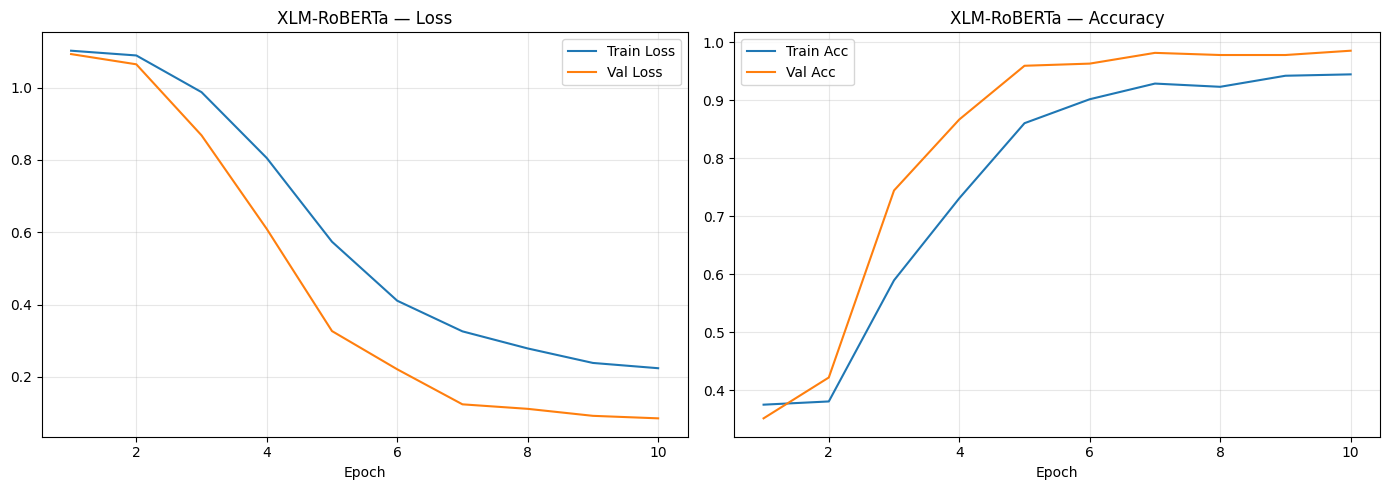

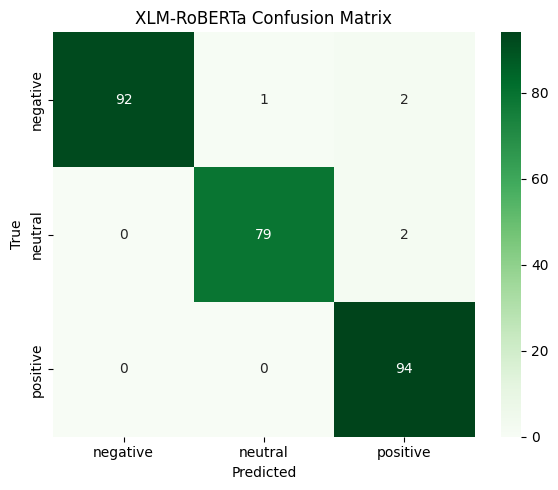

In [13]:
model_xlm.load_state_dict(torch.load(f'{RESULTS_DIR}/xlm_roberta_best.pt'))
_, test_acc_xlm, test_f1_xlm, preds_xlm, labels_xlm, probs_xlm = evaluate(model_xlm, test_dl2, criterion, device)

y_test_bin2 = label_binarize(labels_xlm, classes=[0, 1, 2])
try:
    auc_xlm = roc_auc_score(y_test_bin2, probs_xlm, multi_class='ovr', average='macro')
except:
    auc_xlm = 0.0

f1_weighted_xlm = f1_score(labels_xlm, preds_xlm, average='weighted')

print('=' * 50)
print('XLM-RoBERTa — TEST RESULTS')
print('=' * 50)
print(f'Accuracy:       {test_acc_xlm:.4f}')
print(f'F1 (macro):     {test_f1_xlm:.4f}')
print(f'F1 (weighted):  {f1_weighted_xlm:.4f}')
print(f'AUC-ROC:        {auc_xlm:.4f}')
print(f'Training time:  {xlm_time:.1f}s')
print('=' * 50)
print('\nClassification Report:')
print(classification_report(labels_xlm, preds_xlm, target_names=label_encoder.classes_, digits=4))

# Plot XLM-RoBERTa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range2 = range(1, len(history_xlm['train_loss']) + 1)
axes[0].plot(epochs_range2, history_xlm['train_loss'], label='Train Loss')
axes[0].plot(epochs_range2, history_xlm['val_loss'], label='Val Loss')
axes[0].set_title('XLM-RoBERTa — Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(epochs_range2, history_xlm['train_acc'], label='Train Acc')
axes[1].plot(epochs_range2, history_xlm['val_acc'], label='Val Acc')
axes[1].set_title('XLM-RoBERTa — Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/xlm_roberta_training.png', dpi=150, bbox_inches='tight')
plt.show()

cm_xlm = confusion_matrix(labels_xlm, preds_xlm)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_xlm, annot=True, fmt='d', cmap='Greens', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=ax)
ax.set_title('XLM-RoBERTa Confusion Matrix'); ax.set_ylabel('True'); ax.set_xlabel('Predicted')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/xlm_roberta_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## Computing overall polarity (a simple heuristic)


In [14]:
def compute_overall_polarity(predictions, class_names):
    """Compute overall brand sentiment using threshold-based heuristic (3-class)."""
    unique, counts = np.unique(predictions, return_counts=True)
    count_dict = dict(zip(unique, counts))
    total = len(predictions)

    neg_count = count_dict.get(list(class_names).index('negative'), 0)
    neu_count = count_dict.get(list(class_names).index('neutral'), 0)
    pos_count = count_dict.get(list(class_names).index('positive'), 0)

    neu_pct = neu_count / total

    if neu_pct > 0.85:
        overall = 'Neutral'
    elif pos_count > 1.5 * neg_count:
        overall = 'Positive'
    elif neg_count > 1.5 * pos_count:
        overall = 'Negative'
    else:
        overall = 'Neutral'

    return {
        'overall_polarity': overall,
        'positive_count': int(pos_count),
        'negative_count': int(neg_count),
        'neutral_count': int(neu_count),
        'positive_pct': float(pos_count / total),
        'negative_pct': float(neg_count / total),
        'neutral_pct': float(neu_pct),
    }

# Compute for both models
polarity_bert = compute_overall_polarity(preds_bert, label_encoder.classes_)
polarity_xlm = compute_overall_polarity(preds_xlm, label_encoder.classes_)
polarity_true = compute_overall_polarity(y_test, label_encoder.classes_)

print('Overall Brand Polarity (BERT+BiLSTM predictions):', polarity_bert['overall_polarity'])
print('Overall Brand Polarity (XLM-RoBERTa predictions):', polarity_xlm['overall_polarity'])
print('Overall Brand Polarity (Ground Truth):', polarity_true['overall_polarity'])

# Save polarity results
polarity_results = {
    'bert_bilstm': polarity_bert,
    'xlm_roberta': polarity_xlm,
    'ground_truth': polarity_true,
}
with open(f'{RESULTS_DIR}/overall_polarity_multilingual.json', 'w') as f:
    json.dump(polarity_results, f, indent=2)
print(f'\nPolarity results saved.')

Overall Brand Polarity (BERT+BiLSTM predictions): Neutral
Overall Brand Polarity (XLM-RoBERTa predictions): Neutral
Overall Brand Polarity (Ground Truth): Neutral

Polarity results saved.


## Saving the results


In [ ]:
def save_model_results(model_name, framework, accuracy, f1_macro, f1_weighted, auc_roc,
                       training_time, confusion_mat, history, class_names, polarity, filepath):
    results = {
        'model_name': model_name,
        'framework': framework,
        'timestamp': datetime.now().isoformat(),
        'dataset': {
            'source': 'company_trustpilot_reviews_hard.csv',
            'total_samples': len(df),
            'train_samples': len(X_train),
            'val_samples': len(X_val),
            'test_samples': len(X_test),
            'num_classes': NUM_CLASSES,
            'class_names': list(class_names),
            'languages': list(df['language'].unique()),
        },
        'hyperparameters': {
            'max_len': MAX_LEN,
            'batch_size': BATCH_SIZE,
            'learning_rate': LR,
            'epochs_trained': len(history['train_loss']),
        },
        'metrics': {
            'accuracy': float(accuracy),
            'f1_macro': float(f1_macro),
            'f1_weighted': float(f1_weighted),
            'auc_roc_macro': float(auc_roc),
            'training_time_seconds': float(training_time),
        },
        'confusion_matrix': confusion_mat.tolist(),
        'training_history': {k: [float(v) for v in vals] for k, vals in history.items()},
        'overall_polarity_result': polarity,
    }
    with open(filepath, 'w') as f:
        json.dump(results, f, indent=2)
    print(f'Results saved: {filepath}')

# Save BERT+BiLSTM results
save_model_results(
    'BERT+BiLSTM (Multilingual)', 'PyTorch/HuggingFace',
    test_acc_bert, test_f1_bert, f1_weighted_bert, auc_bert,
    bert_bilstm_time, cm_bert, history_bert, label_encoder.classes_,
    polarity_bert, f'{RESULTS_DIR}/bert_bilstm_multilingual_results.json'
)

# Save XLM-RoBERTa results
save_model_results(
    'XLM-RoBERTa', 'PyTorch/HuggingFace',
    test_acc_xlm, test_f1_xlm, f1_weighted_xlm, auc_xlm,
    xlm_time, cm_xlm, history_xlm, label_encoder.classes_,
    polarity_xlm, f'{RESULTS_DIR}/xlm_roberta_results.json'
)

print('\n✅ All results saved to Google Drive.')

Results saved: /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Multilingual/bert_bilstm_multilingual_results.json
Results saved: /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Multilingual/xlm_roberta_results.json

✅ All results saved to Google Drive.


## Comparing the two models



MULTILINGUAL APPROACH — COMPARISON SUMMARY
Model                          Accuracy     F1(macro)    AUC-ROC      Time(s)   
----------------------------------------------------------------------
BERT+BiLSTM                    0.9778       0.9786       0.9977       268.6     
XLM-RoBERTa                    0.9815       0.9815       0.9997       192.0     


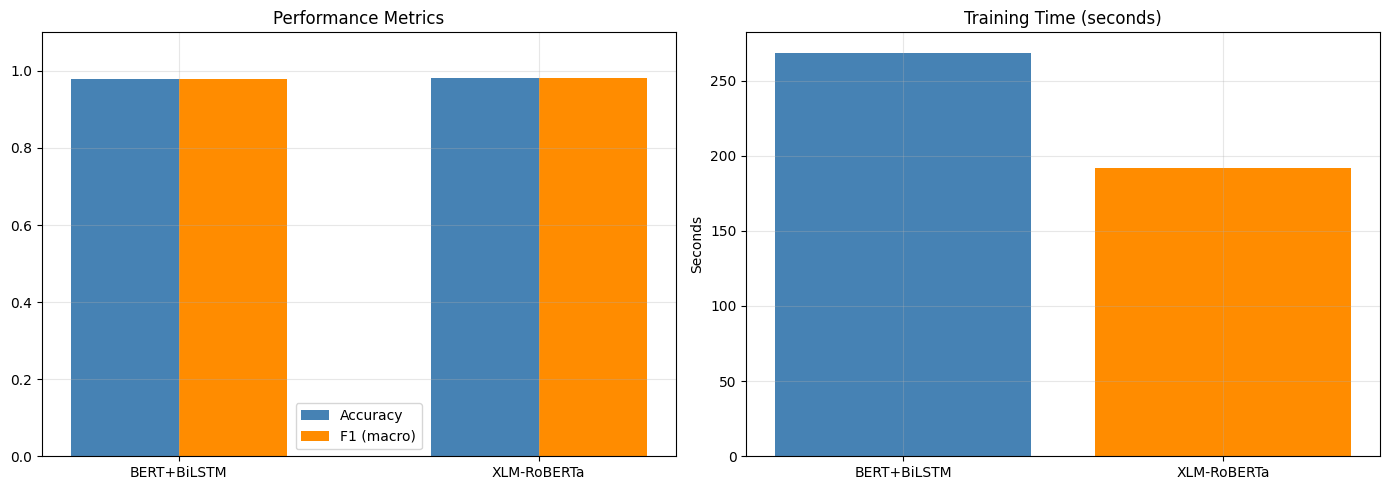


✅ Notebook 1 complete. All results saved to Results_Multilingual/


In [16]:
# Summary table
print('\n' + '=' * 70)
print('MULTILINGUAL APPROACH — COMPARISON SUMMARY')
print('=' * 70)
print(f'{"Model":<30} {"Accuracy":<12} {"F1(macro)":<12} {"AUC-ROC":<12} {"Time(s)":<10}')
print('-' * 70)
print(f'{"BERT+BiLSTM":<30} {test_acc_bert:<12.4f} {test_f1_bert:<12.4f} {auc_bert:<12.4f} {bert_bilstm_time:<10.1f}')
print(f'{"XLM-RoBERTa":<30} {test_acc_xlm:<12.4f} {test_f1_xlm:<12.4f} {auc_xlm:<12.4f} {xlm_time:<10.1f}')
print('=' * 70)

# Comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models = ['BERT+BiLSTM', 'XLM-RoBERTa']
accs = [test_acc_bert, test_acc_xlm]
f1s = [test_f1_bert, test_f1_xlm]
times = [bert_bilstm_time, xlm_time]

x = np.arange(len(models))
axes[0].bar(x - 0.15, accs, 0.3, label='Accuracy', color='steelblue')
axes[0].bar(x + 0.15, f1s, 0.3, label='F1 (macro)', color='darkorange')
axes[0].set_xticks(x); axes[0].set_xticklabels(models)
axes[0].set_ylim(0, 1.1); axes[0].set_title('Performance Metrics'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].bar(models, times, color=['steelblue', 'darkorange'])
axes[1].set_title('Training Time (seconds)'); axes[1].set_ylabel('Seconds'); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/multilingual_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n✅ Notebook 1 complete. All results saved to Results_Multilingual/')